In [1]:
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import spacy

nlp = spacy.load("it_core_news_sm")

In [2]:
query_df = pd.read_csv("Data/query_formulation_df.csv")
query_df.head(10)

,uid,topic_number,serp_id,query,precision@10
0,1,g3t3,serp1,Quali sono i cinque animali tipici dell india,0.2
1,1,g3t2,serp2,Quale è il nome del simbolo al centro della ba...,0.1
2,1,g3t1,serp3,Fiume sacro degli indiani,0.4
3,2,g3t3,serp4,Quali sono i animali dall'India,0.7
4,2,g3t3,serp5,Quali sono i 5 animali tipici dall'India,0.2
5,2,g3t2,serp6,Qual è il nome del simbolo al centro della ban...,0.3
6,2,g3t1,serp8,Come si chiama il fiume sacro agli indiani,0.4
7,2,g3t2,serp7,Qual è il nome del simbolo al centro della b...,0.3
8,3,g3t2,serp12,qual è il nome del centro della bandiera indiana,0.3
9,3,g3t1,serp9,come si chiama il fiume sacro agli indiani,0.4


In [3]:
query_len = []
for _, row in query_df.iterrows():
    query_len.append(len(row["query"].split(" ")))

query_df["query_len"] = query_len

In [4]:
query_df["effective_query"] = [int(p10 >= 0.8) for p10 in query_df["precision@10"]]

In [5]:
query_df.loc[query_df["effective_query"]==1]

,uid,topic_number,serp_id,query,precision@10,query_len,effective_query
17,4,g3t1,serp18,Fiume sacro indiano,0.8,3,1
38,8,g3t1,serp53,Fiume sacro India,0.8,3,1
39,8,g3t1,serp52,Fiume sacro India,0.8,3,1


<Axes: xlabel='effective_query', ylabel='query_len'>

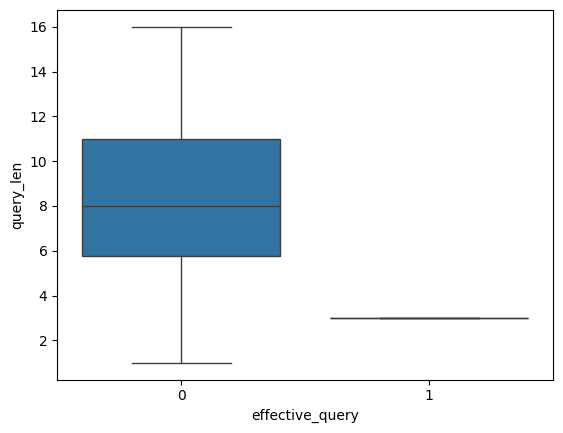

In [6]:
sns.boxplot(data=query_df, x="effective_query", y="query_len")

In [7]:
ITaoa = pd.read_excel("Resources/ItAoA.xlsx")
ITaoa.head()

,The database is organized as follows:
0,NaN
1,Eng_Word: The English translation of the Itali...
2,Ita_Word: The Italian noun of each word includ...
3,WordClass: The grammatical role assigned to ea...
4,M_AoA: The mean of age of acquisition ratings.


In [8]:
query_df.groupby("precision@10")["serp_id"]